In [1]:
#etapa01
!pip install pandas matplotlib seaborn scikit-learn xgboost openpyxl catboost statsmodels shap

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached tzdata-2025.2-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.2.3-py3-none-any.whl.metadata (5.0 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached patsy-1.0.1-py2.py3-none-any.whl.metadata (3.3 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached cloudpickle-3.1.1-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 10.7 MB/s  0:00:01m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 18.6 MB/s  0:00:00m0:00:0100:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
#etapa02
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from scipy.stats import kstest
# 1. Carregar os dados
df = pd.read_excel('LP.dados.turma(01).xlsx')

# 2. Limpar vírgulas, converter pra float, arredondar e finalmente pra int
for col in ['INICIAL', 'INTERMEDIARIO', 'FINAL', 'PROFICIENCIA']:
    df[col] = (
        df[col]
          .astype(str)                          # garante que é string
          .str.replace(',', '', regex=False)     # remove vírgulas (se houver)
          .astype(float)                         # converte pra float
          .round(0)                              # arredonda pra inteiro mais próximo
          .astype(int)                           # converte pra int
    )


In [3]:
#etapa03
from sklearn.model_selection import train_test_split
# 3. Definir X e y
X = df[['INICIAL', 'INTERMEDIARIO', 'FINAL']]
display(X)
y = df['PROFICIENCIA']
display(y)

# 4. Split 70/30
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42
)

print(f'Treino:  X_train={X_train.shape}, y_train={y_train.shape}')
print(f'Teste:   X_test={X_test.shape}, y_test={y_test.shape}')


,INICIAL,INTERMEDIARIO,FINAL
0,56,60,63
1,47,51,52
2,64,70,71
3,57,56,55
4,41,58,60
...,...,...,...
731,58,67,66
732,70,68,73
733,72,70,78
734,73,73,77


0      258
1      211
2      271
3      250
4      230
      ... 
731    260
732    274
733    280
734    275
735    243
Name: PROFICIENCIA, Length: 736, dtype: int64

Treino:  X_train=(515, 3), y_train=(515,)
Teste:   X_test=(221, 3), y_test=(221,)


In [4]:
#ETAPA04
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score



# Regressão Linear
lr = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)
mape_lr = (np.abs((y_test - y_pred_lr) / y_test)).mean() * 100

print(f'LinearRegression → R²={r2_lr:.3f}, MAE={mae_lr:.2f}, RMSE={rmse_lr:.2f}, MAPE={mape_lr:.2f}%')


LinearRegression → R²=0.529, MAE=8.82, RMSE=11.20, MAPE=3.54%


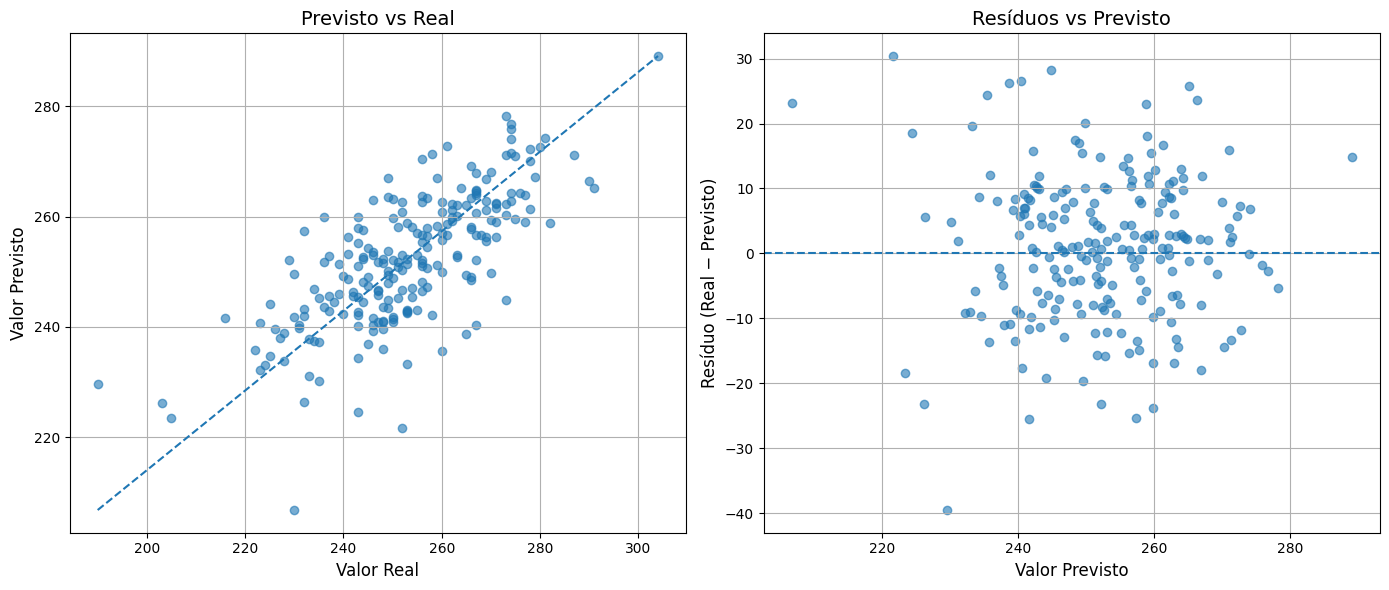

In [5]:
#ETAPA 05
import matplotlib.pyplot as plt

#Configura os subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
residuals = y_test - y_pred_lr
# --- Gráfico 1: Previsto vs Real ---
ax = axes[0]
ax.scatter(y_test, y_pred_lr, alpha=0.6)
ax.plot([y_test.min(), y_test.max()], [y_pred_lr.min(), y_pred_lr.max()], linestyle='--')
ax.set_xlabel('Valor Real', fontsize=12)
ax.set_ylabel('Valor Previsto', fontsize=12)
ax.set_title('Previsto vs Real', fontsize=14)
ax.grid(True)
ax.tick_params(axis='both', which='major', labelsize=10)

# --- Gráfico 2: Resíduos vs Previsto ---
ax = axes[1]
ax.scatter(y_pred_lr, residuals, alpha=0.6)
ax.axhline(0, linestyle='--')
ax.set_xlabel('Valor Previsto', fontsize=12)
ax.set_ylabel('Resíduo (Real − Previsto)', fontsize=12)
ax.set_title('Resíduos vs Previsto', fontsize=14)
ax.grid(True)
ax.tick_params(axis='both', which='major', labelsize=10)

plt.tight_layout()
plt.show()


,INICIAL,INTERMEDIARIO,FINAL,PROFICIENCIA
265,64,67,69,257
537,58,74,71,258
260,52,50,72,240
137,68,65,69,258
479,61,66,68,250
...,...,...,...,...
71,47,25,66,244
106,68,69,76,266
270,67,68,80,262
435,61,62,72,237


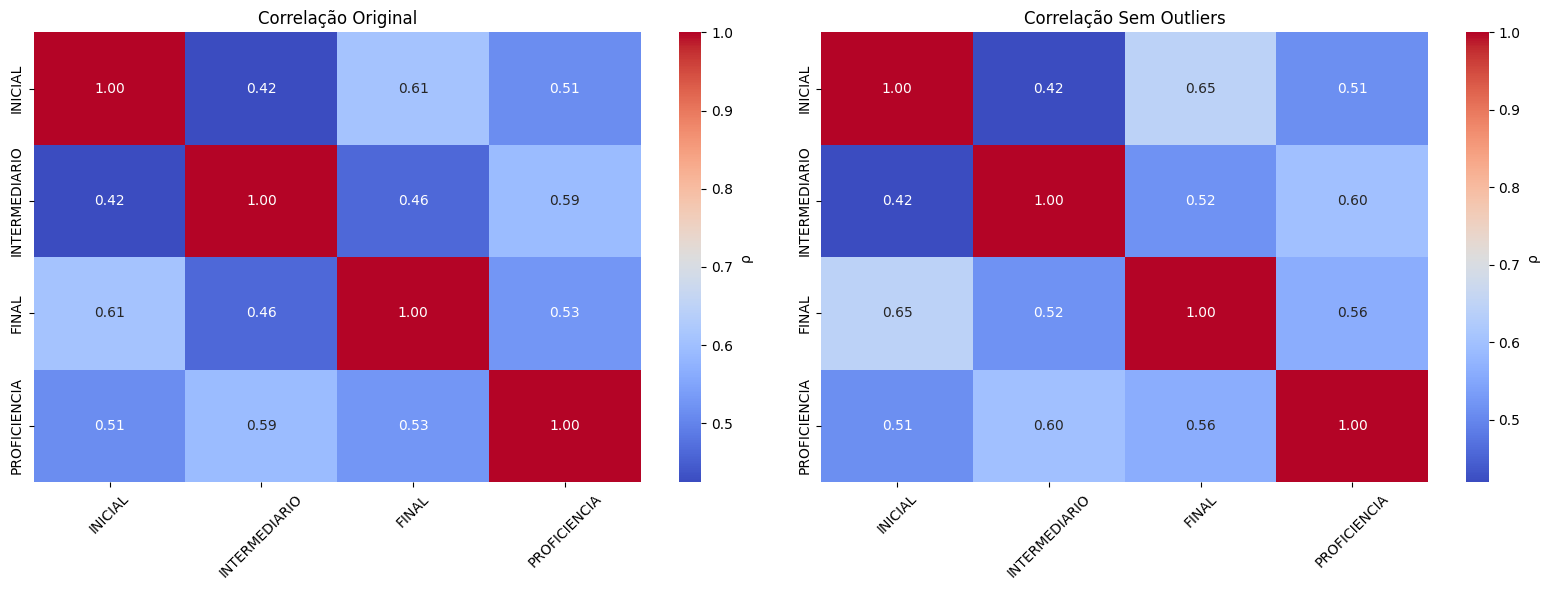

In [6]:
#ETAPA06
# 1. Reunir X_train e y_train
df_train = pd.concat([X_train, y_train], axis=1)
display(df_train)

# 2. Análise Exploratória e Tratamento de Outliers
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 2.1 Matriz de correlação original
corr_orig = df_train.corr()

# 2.2 Remoção de outliers pelo método IQR
Q1 = df_train.quantile(0.25)
Q3 = df_train.quantile(0.75)
IQR = Q3 - Q1
mask = ~((df_train < (Q1 - 1.5 * IQR)) | (df_train > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df_train[mask]

# 2.3 Matriz de correlação sem outliers
corr_clean = df_clean.corr()

# 2.4 Plotagem
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    corr_orig,
    annot=True, fmt='.2f',
    cmap='coolwarm',
    cbar_kws={'label': 'ρ'},
    ax=axes[0]
)
axes[0].set_title('Correlação Original')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(
    corr_clean,
    annot=True, fmt='.2f',
    cmap='coolwarm',
    cbar_kws={'label': 'ρ'},
    ax=axes[1]
)
axes[1].set_title('Correlação Sem Outliers')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


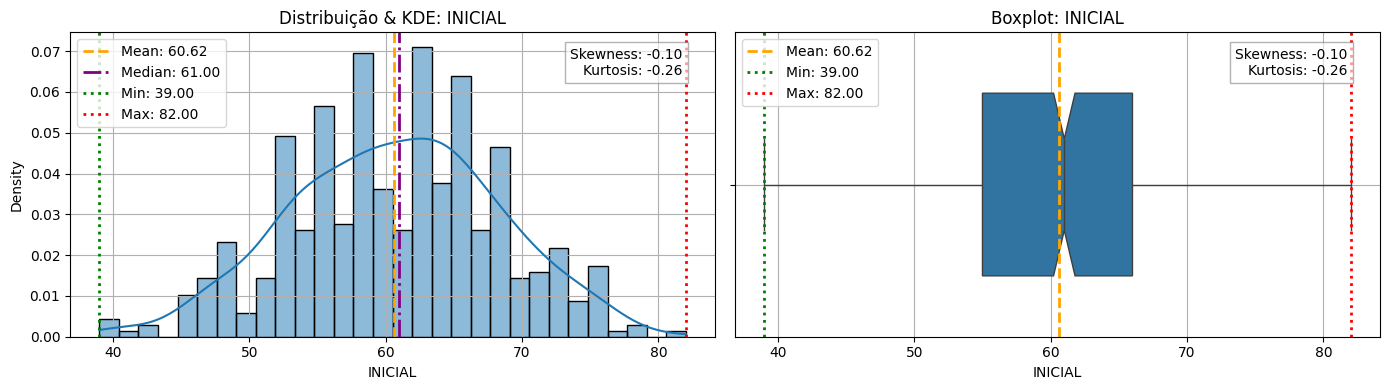

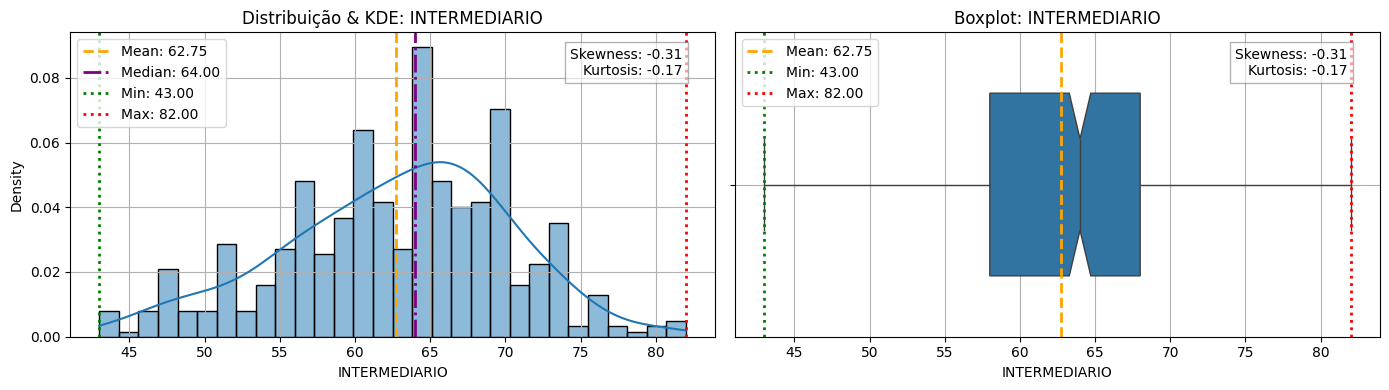

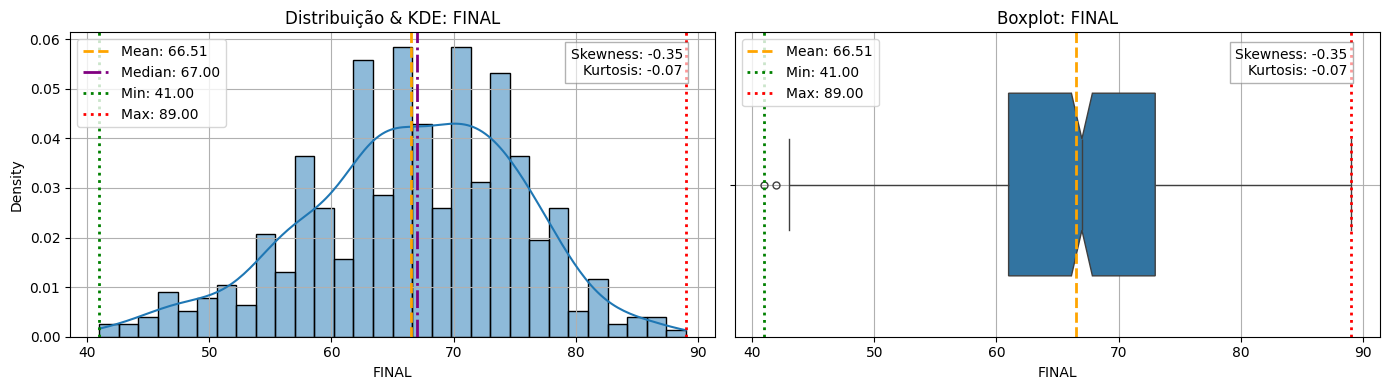

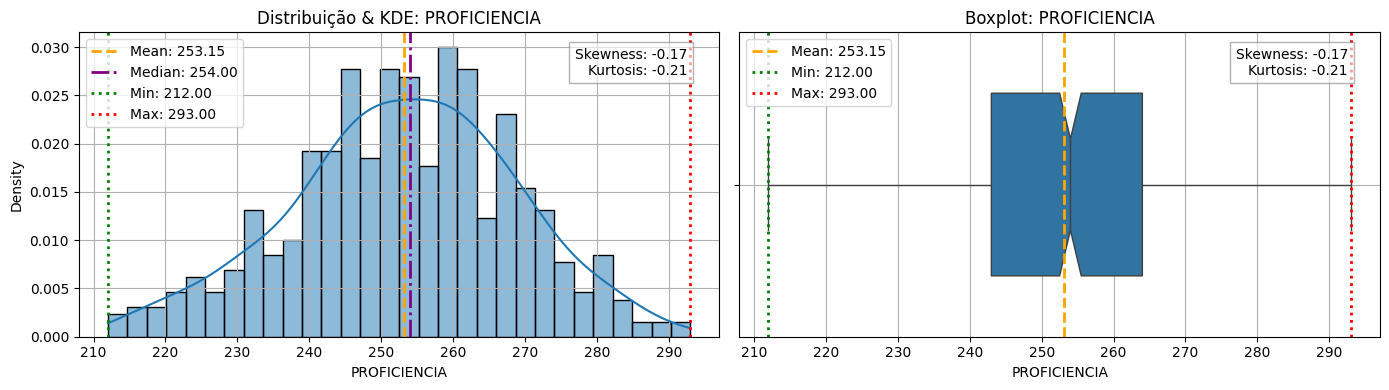

In [7]:
#ETAPA07
# 3. Estatísticas Descritivas aprimoradas
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



for col in df_clean.columns:
    vals = df_clean[col]
    mean    = vals.mean()
    median  = vals.median()
    min_val = vals.min()
    max_val = vals.max()
    skew    = vals.skew()
    kurt    = vals.kurtosis()

    fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 4))

    # --- Histograma + KDE ---
    sns.histplot(vals, bins=30, kde=True, stat='density', ax=ax_hist)
    ax_hist.axvline(mean,   color='orange', linestyle='--', linewidth=2, label=f'Mean: {mean:.2f}')
    ax_hist.axvline(median, color='purple', linestyle='-.', linewidth=2, label=f'Median: {median:.2f}')
    ax_hist.axvline(min_val, color='green', linestyle=':', linewidth=2, label=f'Min: {min_val:.2f}')
    ax_hist.axvline(max_val, color='red',   linestyle=':', linewidth=2, label=f'Max: {max_val:.2f}')
    ax_hist.text(
        0.95, 0.95,
        f'Skewness: {skew:.2f}\nKurtosis: {kurt:.2f}',
        transform=ax_hist.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray')
    )
    ax_hist.set_title(f'Distribuição & KDE: {col}')
    ax_hist.legend()
    ax_hist.grid(True)

    # --- Boxplot notch ---
    sns.boxplot(x=vals, notch=True, width=0.6, fliersize=5, ax=ax_box)
    ax_box.axvline(mean,   color='orange', linestyle='--', linewidth=2, label=f'Mean: {mean:.2f}')
    ax_box.axvline(min_val, color='green', linestyle=':', linewidth=2, label=f'Min: {min_val:.2f}')
    ax_box.axvline(max_val, color='red',   linestyle=':', linewidth=2, label=f'Max: {max_val:.2f}')
    ax_box.text(
        0.95, 0.95,
        f'Skewness: {skew:.2f}\nKurtosis: {kurt:.2f}',
        transform=ax_box.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray')
    )
    ax_box.set_title(f'Boxplot: {col}')
    ax_box.legend()
    ax_box.grid(True)

    plt.tight_layout()
    plt.show()


In [8]:
#ETAPA08
# =========================================================
# 5. Validação Cruzada e Tabela Comparativa de Modelos
# =========================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor          # ← novo
from IPython.display import display

# ---------------------- dados limpos ----------------------
X_clean = df_clean.iloc[:, :-1]
y_clean = df_clean.iloc[:, -1]

# ------------------ validação e métricas -----------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'r2'  : 'r2',
    'mae' : 'neg_mean_absolute_error',
    'mse' : 'neg_mean_squared_error',
    'mape': 'neg_mean_absolute_percentage_error'
}

# ----------------------- modelos -------------------------
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest'    : RandomForestRegressor(
                            n_estimators=100, random_state=42
                        ),
    'MLPRegressor'    : MLPRegressor(
                            hidden_layer_sizes=(100,),
                            max_iter=1000, random_state=42
                        ),
    'XGBRegressor'    : XGBRegressor(
                            objective='reg:squarederror',
                            random_state=42
                        ),
    'CatBoost'        : CatBoostRegressor(
                            iterations=500,
                            learning_rate=0.05,
                            depth=6,
                            loss_function='RMSE',
                            random_seed=42,
                            verbose=False            # silencia saída
                        )
}

# --------------- cross‑validation e resultados ------------
results = []
for name, model in models.items():
    scores = cross_validate(
        model, X_clean, y_clean,
        scoring=scoring,
        cv=kf,
        n_jobs=-1,
        return_train_score=False
    )
    results.append({
        'Model'   : name,
        'R2'      : scores['test_r2'].mean(),
        'MAE'     : -scores['test_mae'].mean(),
        'RMSE'    : np.sqrt(-scores['test_mse'].mean()),
        'MAPE (%)': -scores['test_mape'].mean() * 100
    })

# -------------- tabela comparativa final -----------------
df_results = (
    pd.DataFrame(results)
      .set_index('Model')
      .sort_values('R2', ascending=False)
      .round({'R2': 4, 'MAE': 3, 'RMSE': 3, 'MAPE (%)': 2})
)

display(df_results)



/opt/conda/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,R2,MAE,RMSE,MAPE (%)
Model,,,,
LinearRegression,0.4499,9.030,11.362,3.60
CatBoost,0.3160,10.045,12.698,4.00
RandomForest,0.3021,10.300,12.842,4.11
XGBRegressor,0.1098,11.696,14.527,4.65
MLPRegressor,-0.5461,15.351,19.080,6.11


In [9]:
# ETAPA09=============================================================
# 6. Validação cruzada e tabela comparativa (agora com CatBoost)
# =============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    KFold, RandomizedSearchCV, cross_val_predict
)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor              # ← NOVO
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)

# --- Funções auxiliares de erro ---------------------------------
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# --- Dicionário de modelos e espaços de busca -------------------
models = {
    'LinearRegression': {
        'est'   : LinearRegression(),
        'params': {}
    },
    'RandomForest': {
        'est'   : RandomForestRegressor(random_state=42),
        'params': {
            'n_estimators'    : [100, 200, 500],
            'max_depth'       : [None, 5, 10],
            'min_samples_leaf': [1, 2, 5],
            'max_features'    : ['auto', 'sqrt', 0.5]
        }
    },
    'MLPRegressor': {
        'est'   : MLPRegressor(random_state=42),
        'params': {
            'hidden_layer_sizes': [(50,), (100,), (50, 50)],
            'activation'        : ['relu', 'tanh'],
            'alpha'             : [1e-4, 1e-3, 1e-2],
            'learning_rate_init': [1e-3, 1e-2],
            'max_iter'          : [200, 500]
        }
    },
    'XGBRegressor': {
        'est'   : XGBRegressor(random_state=42, use_label_encoder=False, verbosity=0),
        'params': {
            'n_estimators'   : [100, 200, 500],
            'max_depth'      : [3, 5, 7],
            'learning_rate'  : [0.01, 0.1, 0.2],
            'subsample'      : [0.6, 0.8, 1.0],
            'colsample_bytree': [0.6, 0.8, 1.0]
        }
    },
    'CatBoost': {                               # ← NOVO BLOCO
        'est'   : CatBoostRegressor(
                     loss_function='RMSE',
                     random_seed=42,
                     verbose=False
                  ),
        'params': {
            'iterations'    : [300, 500, 800],
            'depth'         : [4, 6, 8],
            'learning_rate' : [0.02, 0.05, 0.1],
            'l2_leaf_reg'   : [1, 3, 5]
        }
    }
}

# --- Configuração de validação cruzada --------------------------
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

# --- Loop principal: tuning e avaliação -------------------------
results = []

for name, mp in models.items():
    est, params = mp['est'], mp['params']
    
    # 1. Busca de hiperparâmetros (se houver grade)
    if params:
        search = RandomizedSearchCV(
            est, param_distributions=params, n_iter=20,
            cv=outer_cv, scoring='r2', n_jobs=-1, random_state=42, verbose=0
        )
        search.fit(X_clean, y_clean)
        best_est = search.best_estimator_
        print(f"{name}  | best CV R²: {search.best_score_:.4f}")
    else:
        best_est = est.fit(X_clean, y_clean)
        print(f"{name}  | sem otimização de hiperparâmetros.")
    
    # 2. Predições out‑of‑fold (sobre o CONJUNTO DE TESTE verdadeiro)
    y_pred = cross_val_predict(
        best_est, X_test, y_test, cv=outer_cv, n_jobs=-1
    )

    # 3. Métricas
    results.append({
        'Model'  : name,
        'R2'     : r2_score(y_test, y_pred),
        'MAE'    : mean_absolute_error(y_test, y_pred),
        'RMSE'   : rmse(y_test, y_pred),
        'MAPE %' : mape(y_test, y_pred)
    })

# --- Tabela comparativa final -----------------------------------
df_comparacao = (
    pd.DataFrame(results)
      .set_index('Model')
      .sort_values('R2', ascending=False)
      .round({'R2':4, 'MAE':3, 'RMSE':3, 'MAPE %':2})
)

display(df_comparacao)



LinearRegression  | sem otimização de hiperparâmetros.


/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
45 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
27 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.13/site-packages/sklearn/base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/opt/conda/lib/python3.13/site-packages/sklearn/base.py", line 471, in _validate_params
    validate_pa

RandomForest  | best CV R²: 0.4269


/opt/conda/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptro

MLPRegressor  | best CV R²: 0.0222
XGBRegressor  | best CV R²: 0.3993
CatBoost  | best CV R²: 0.4257


,R2,MAE,RMSE,MAPE %
Model,,,,
XGBRegressor,0.5915,8.068,10.426,3.24
CatBoost,0.5849,8.190,10.510,3.29
RandomForest,0.5660,8.413,10.746,3.38
LinearRegression,0.5083,8.970,11.438,3.61
MLPRegressor,-2.3770,24.586,29.976,9.64


In [10]:
#ETAPA 11
# 0) Se necessário, instale as bibliotecas:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# --- 1) Defina as funções de métrica ---
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# --- 3) Configuração dos modelos e hiperparâmetros ---
models = [
    # (nome, pipeline, espaço de busca)
    ("LinearRegression",
        Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        {
            # LinearRegression não tem hiperparâmetros principais a buscar
        }
    ),

    ("RandomForest",
        Pipeline([("scaler", StandardScaler()), ("model", RandomForestRegressor(random_state=42))]),
        {
            "model__n_estimators": [100, 200, 500],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_leaf": [1, 2, 5],
            "model__max_features": ["auto", "sqrt", 0.5]
        }
    ),

    ("MLPRegressor",
        Pipeline([("scaler", StandardScaler()), ("model", MLPRegressor(max_iter=500, random_state=42))]),
        {
            "model__hidden_layer_sizes": [(50,), (100,), (50,50)],
            "model__activation": ["relu", "tanh"],
            "model__alpha": [0.0001, 0.001, 0.01],
            "model__learning_rate_init": [0.001, 0.01]
        }
    ),

    ("XGBRegressor",
        Pipeline([("scaler", StandardScaler()), ("model", XGBRegressor(objective="reg:squarederror", random_state=42))]),
        {
            "model__n_estimators": [100, 200, 500],
            "model__max_depth": [3, 5, 7],
            "model__learning_rate": [0.01, 0.1, 0.2],
            "model__subsample": [0.6, 0.8, 1.0]
        }
    ),


    ("CatBoost",
        Pipeline([("scaler", StandardScaler()), ("model", CatBoostRegressor(verbose=0, random_state=42))]),
        {
            "model__iterations": [200, 500],
            "model__depth": [4, 6, 8],
            "model__learning_rate": [0.01, 0.1],
            "model__l2_leaf_reg": [1, 3, 5]
        }
    )
]

# --- 4) Loop de RandomizedSearchCV + avaliação ---
results = []

cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe, params in models:
    if params:
        search = RandomizedSearchCV(
            pipe, params,
            n_iter=10,
            cv=cv,
            scoring="r2",
            n_jobs=-1,
            random_state=42
        )
    else:
        # se não há params, só ajusta direto
        search = pipe

    # Treina
    search.fit(X_clean, y_clean)
    best_model = search.best_estimator_ if params else search

    # Predições em teste
    y_pred = best_model.predict(X_test)

    # Calcula métricas
    results.append({
        "Model": name,
        "R2":  round(r2_score(y_test, y_pred), 4),
        "MAE": round(mean_absolute_error(y_test, y_pred), 4),
        "RMSE": round(rmse(y_test, y_pred), 4),
        "MAPE (%)": round(mape(y_test, y_pred), 4)
    })

# --- 5) Tabela comparativa ---
df_results = pd.DataFrame(results).set_index("Model")
print(df_results)


/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
20 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
17 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.13/site-packages/sklearn/base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/opt/conda/lib/python3.13/site-packages/sklearn/pipeline.py", line 663, in fit
    self._final_estimator.fit(Xt, y, **la

                      R2     MAE     RMSE  MAPE (%)
Model                                              
LinearRegression  0.5256  8.9036  11.2349    3.5599
RandomForest      0.5566  8.6730  10.8625    3.4734
MLPRegressor      0.5055  8.8397  11.4709    3.5707
XGBRegressor      0.5330  8.8317  11.1475    3.5411
CatBoost          0.5718  8.5100  10.6745    3.4034


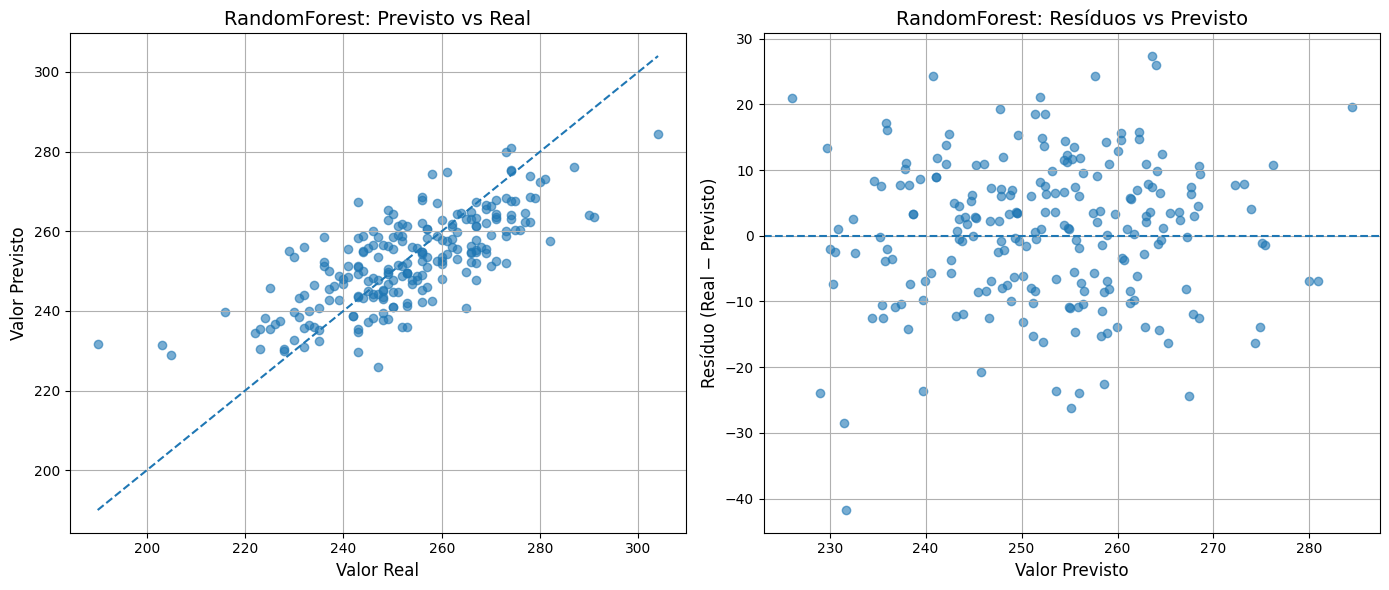

In [11]:
#ETAPA12
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

best_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=42
    ))
])

# --- 1) Ajuste final em toda a base limpa (X_clean, y_clean) ---
X_clean = df_clean.iloc[:, :-1]
y_clean = df_clean.iloc[:, -1]

best_rf.fit(X_clean, y_clean)

# --- 2) Predição no conjunto de teste (X_test, y_test) ---
y_pred    = best_rf.predict(X_test)
residuals = y_test - y_pred

# --- 3) Plot dos dois gráficos lado a lado ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Previsto vs Real
ax = axes[0]
ax.scatter(y_test, y_pred, alpha=0.6)
# reta identidade y = x
ax.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
ax.set_xlabel('Valor Real',   fontsize=12)
ax.set_ylabel('Valor Previsto',fontsize=12)
ax.set_title('RandomForest: Previsto vs Real', fontsize=14)
ax.grid(True)

# Gráfico 2: Resíduos vs Previsto
ax = axes[1]
ax.scatter(y_pred, residuals, alpha=0.6)
ax.axhline(0, linestyle='--')  # linha de referência em resíduo = 0
ax.set_xlabel('Valor Previsto',              fontsize=12)
ax.set_ylabel('Resíduo (Real − Previsto)',   fontsize=12)
ax.set_title('RandomForest: Resíduos vs Previsto', fontsize=14)
ax.grid(True)

plt.tight_layout()
plt.show()


R²:   0.5413
RMSE: 11.0479
MAE:  8.8177
MAPE: 3.53%


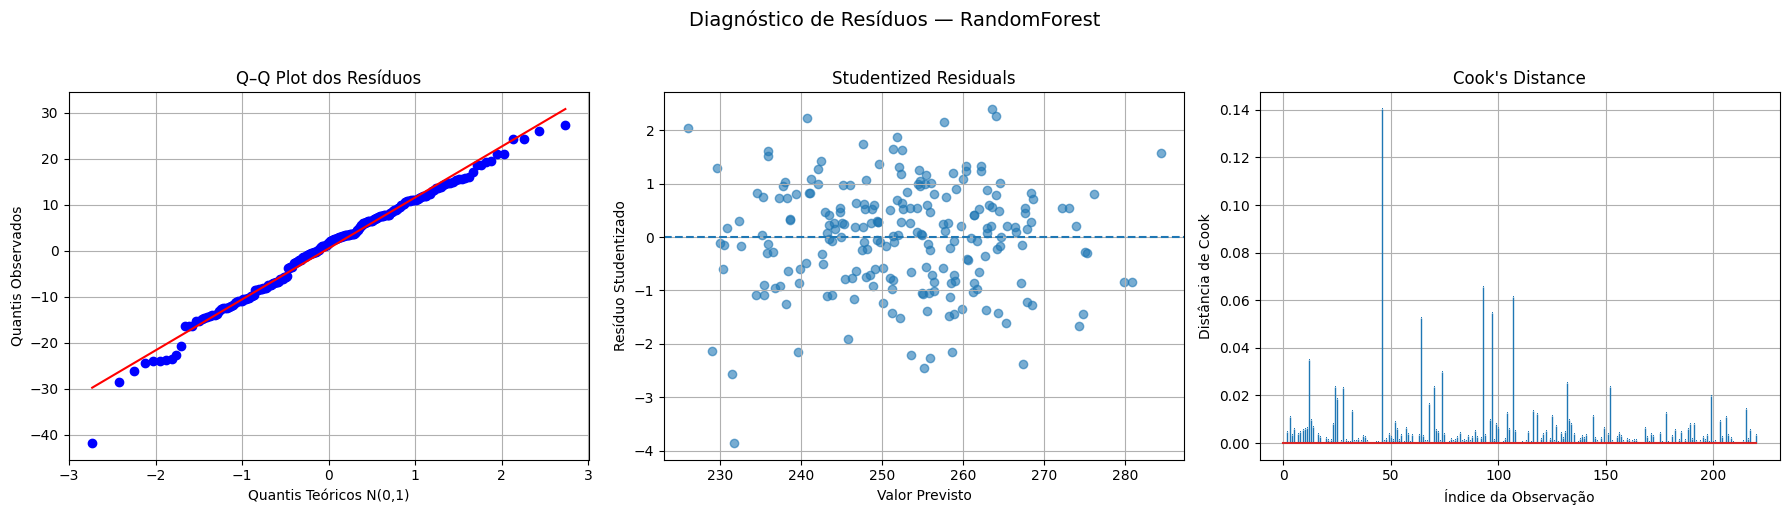

In [12]:
#ETAPA 14
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# --- 1) Ajuste final e predição ---
best_rf.fit(X_clean, y_clean)
y_pred    = best_rf.predict(X_test)
residuals = y_test - y_pred

# --- 2) Cálculo das métricas ---
r2   = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"MAPE: {mape:.2f}%")

# --- 3) Ajuste OLS para medidas de influência ---
X_inf = sm.add_constant(y_pred)
ols   = sm.OLS(y_test, X_inf).fit()
infl  = ols.get_influence()
studentized_resid = infl.resid_studentized_external
cooks_d, _        = infl.cooks_distance

# --- 4) Cria uma figura com 1x3 subplots ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 4.1) Q–Q Plot dos resíduos
stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Q–Q Plot dos Resíduos", fontsize=12)
axes[0].set_xlabel("Quantis Teóricos N(0,1)", fontsize=10)
axes[0].set_ylabel("Quantis Observados", fontsize=10)
axes[0].grid(True)

# 4.2) Studentized residuals vs Valor Previsto
axes[1].scatter(y_pred, studentized_resid, alpha=0.6)
axes[1].axhline(0, linestyle='--')
axes[1].set_title("Studentized Residuals", fontsize=12)
axes[1].set_xlabel("Valor Previsto", fontsize=10)
axes[1].set_ylabel("Resíduo Studentizado", fontsize=10)
axes[1].grid(True)

# 4.3) Cook's Distance
markerline, stemlines, baseline = axes[2].stem(
    np.arange(len(cooks_d)),
    cooks_d,
    markerfmt=','
)
plt.setp(stemlines, 'linewidth', 1)
axes[2].set_title("Cook's Distance", fontsize=12)
axes[2].set_xlabel("Índice da Observação", fontsize=10)
axes[2].set_ylabel("Distância de Cook", fontsize=10)
axes[2].grid(True)

# 5) Ajustes finais de layout
plt.suptitle("Diagnóstico de Resíduos — RandomForest", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
#ETAPA 15
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import PolynomialFeatures, PowerTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)
from scipy.stats import randint, uniform
import scipy.stats as stats
import statsmodels.api as sm

# --- 0) Prepare os dados a partir de df_clean ---
X_clean = df_clean.iloc[:, :-1]
y_clean = df_clean.iloc[:, -1]

# 2) RandomizedSearch para RandomForest
param_dist = {
    'n_estimators': randint(100, 1000),
    'max_depth': randint(5, 50),
    'min_samples_leaf': randint(1, 10),
    'max_features': uniform(0.3, 0.7)
}
rand_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)
rand_search.fit(X_clean, y_clean)
best_rf = rand_search.best_estimator_

# Dicionário para manter todos os modelos candidatos
models = {'baseline': best_rf}

# 3) Engenharia de features: interações polinomiais nas top 5 features
feat_imp = best_rf.feature_importances_
feat_names = X_clean.columns.to_numpy()
top_feats = feat_names[np.argsort(feat_imp)[::-1][:5]].tolist()
poly = PolynomialFeatures(degree=3, interaction_only=True, include_bias=False)

Xtr_poly = np.hstack([X_clean.values,
                      poly.fit_transform(X_clean[top_feats])])
Xte_poly = np.hstack([X_test.values,
                      poly.transform(X_test[top_feats])])

rf_poly = RandomForestRegressor(**rand_search.best_params_, random_state=42)
models['poly_int'] = (rf_poly, Xtr_poly, Xte_poly)

# 4) PowerTransformer pipeline
pipe_pt = make_pipeline(
    PowerTransformer(method='yeo-johnson', standardize=True),
    RandomForestRegressor(**rand_search.best_params_, random_state=42)
)
models['power_yj'] = pipe_pt

# 5) Stacking com RF e XGB como base, Ridge como meta
stack = StackingRegressor(
    estimators=[
        ('rf', best_rf),
        ('xgb', XGBRegressor(random_state=42, n_estimators=200))
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    n_jobs=-1
)
models['stacking'] = stack

# 6) Filtragem de outliers influentes via Cook's distance no treino
y_clean_pred = best_rf.predict(X_clean)
X_inf = sm.add_constant(y_clean_pred)
ols = sm.OLS(y_clean, X_inf).fit()
cooks_d_train = ols.get_influence().cooks_distance[0]
threshold = 4 / (len(y_clean) - 2)
keep_idx = np.where(cooks_d_train < threshold)[0]
X_clean_filt = X_clean.iloc[keep_idx]
y_clean_filt = y_clean.iloc[keep_idx]
rf_filt = RandomForestRegressor(**rand_search.best_params_, random_state=42)
models['filtered'] = (rf_filt, X_clean_filt, X_test)

# 7) Avaliação de todos os modelos
print("Modelo       R²      RMSE    MAE     MAPE")
for name, spec in models.items():
    if name == 'poly_int':
        model, Xtr, Xte = spec
        model.fit(Xtr, y_clean)
        y_pred = model.predict(Xte)
    elif name == 'filtered':
        model, Xtr_f, Xte = spec
        model.fit(Xtr_f, y_clean_filt)
        y_pred = model.predict(X_test)
    else:
        model = spec
        model.fit(X_clean, y_clean)
        y_pred = model.predict(X_test)

    r2   = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae  = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    print(f"{name:12s} {r2:6.4f}  {rmse:7.4f}  {mae:7.4f}  {mape:7.2f}%")

# 8) Plot dos diagnósticos para o melhor modelo (baseline) lado a lado
y_pred_base = best_rf.predict(X_test)
residuals = y_test - y_pred_base

# OLS para influências no teste
X_inf_t = sm.add_constant(y_pred_base)
ols_t   = sm.OLS(y_test, X_inf_t).fit()
infl_t  = ols_t.get_influence()
studentized_resid = infl_t.resid_studentized_external
cooks_d = infl_t.cooks_distance[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Q–Q Plot
stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Q–Q Plot dos Resíduos")
axes[0].grid(True)

# Studentized residuals
axes[1].scatter(y_pred_base, studentized_resid, alpha=0.6)
axes[1].axhline(0, linestyle='--')
axes[1].set_title("Studentized Residuals vs Previsto")
axes[1].grid(True)

# Cook's distance
markerline, stemlines, baseline = axes[2].stem(
    np.arange(len(cooks_d)), cooks_d, markerfmt=','
)
plt.setp(stemlines, 'linewidth', 1)
axes[2].axhline(threshold, color='red', linestyle='--',
                label=f"Threshold {threshold:.3f}")
axes[2].set_title("Cook's Distance")
axes[2].legend()
axes[2].grid(True)

plt.suptitle("Diagnóstico de Resíduos — RandomForest", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
# ETAPA 16          ============================================================
#   MÉTRICAS COMPLETAS: train‑CV, val‑CV, gap, teste
#   (baseline, poly_int, power_yj, stacking, filtered)
# ============================================================

import numpy as np, pandas as pd
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)

# ---------- funções auxiliares ----------
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

scorers = {
    'r2' : 'r2',
    'mae': 'neg_mean_absolute_error',
    'mse': 'neg_mean_squared_error'
}
cv_outer = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_report(model, Xtr, ytr, Xts, yts, label):
    """Retorna dicionário com R² train‑CV, R² val‑CV, gap e métricas de teste."""
    cv_res = cross_validate(model, Xtr, ytr,
                            cv=cv_outer, scoring=scorers,
                            return_train_score=True, n_jobs=-1)
    
    r2_tr = cv_res['train_r2'].mean()
    r2_va = cv_res['test_r2'].mean()
    gap   = r2_tr - r2_va

    # ajuste final + métricas em teste
    model.fit(Xtr, ytr)
    y_pred = model.predict(Xts)
    return {
        'Modelo'     : label,
        'R2 train CV': r2_tr,
        'R2 val CV'  : r2_va,
        'gap'        : gap,
        'R2 test'    : r2_score(yts, y_pred),
        'RMSE'       : rmse(yts, y_pred),
        'MAE'        : mean_absolute_error(yts, y_pred),
        'MAPE %'     : mape(yts, y_pred)
    }

# ---------- PREPAROS PARA OS CINCO MODELOS ----------

# 1) baseline ..............................
baseline = best_rf

# 2) poly_int .............................
X_poly_all  = np.hstack([X_clean.values,
                         poly.fit_transform(X_clean[top_feats])])
X_test_poly = np.hstack([X_test.values,
                         poly.transform(X_test[top_feats])])
rf_poly.fit(X_poly_all, y_clean)         # garante .fit antes do relatório

# 3) power_yj .............................
pipe_pt.fit(X_clean, y_clean)

# 4) stacking .............................
stack.fit(X_clean, y_clean)

# 5) filtered .............................
rf_filt.fit(X_clean_filt, y_clean_filt)

# ---------- GERA RELATÓRIOS ----------
reports = []
reports.append(cv_report(baseline      , X_clean        , y_clean        , X_test      , y_test, 'baseline'))
reports.append(cv_report(rf_poly       , X_poly_all     , y_clean        , X_test_poly , y_test, 'poly_int'))
reports.append(cv_report(pipe_pt       , X_clean        , y_clean        , X_test      , y_test, 'power_yj'))
reports.append(cv_report(stack         , X_clean        , y_clean        , X_test      , y_test, 'stacking'))
reports.append(cv_report(rf_filt       , X_clean_filt   , y_clean_filt   , X_test      , y_test, 'filtered'))

# ---------- TABELA FINAL ----------
df_gap = (pd.DataFrame(reports)
            .set_index('Modelo')
            .round({'R2 train CV':4, 'R2 val CV':4, 'gap':4,
                    'R2 test':4, 'RMSE':3, 'MAE':3, 'MAPE %':2})
            .sort_values('R2 val CV', ascending=False))

display(df_gap)



In [ ]:
#ETAPA17
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm

# ---------- Dados ----------
X_clean = df_clean.iloc[:, :-1]
y_clean = df_clean.iloc[:, -1]
# Supondo que X_test e y_test já estejam definidos a partir de um split anterior

# ---------- Funções métricas ----------
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# ---------- Configurações de CV ----------
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {'r2':'r2', 'neg_mae':'neg_mean_absolute_error', 'neg_mse':'neg_mean_squared_error'}

# ---------- 1) Random Forest base regularizado ----------
rf_base = RandomForestRegressor(
    n_estimators=300, max_depth=12,
    min_samples_leaf=2, max_features='sqrt',
    random_state=42, n_jobs=-1
)
rf_base.fit(X_clean, y_clean)

# ---------- 2) poly_int_v2 (top‑3 interações grau 2) ----------
imp   = rf_base.feature_importances_
names = X_clean.columns.to_numpy()
top3  = names[np.argsort(imp)[::-1][:3]]
poly2 = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)

X_poly_all   = np.hstack([X_clean.values, poly2.fit_transform(X_clean[top3])])
X_test_poly  = np.hstack([X_test.values,  poly2.transform(X_test[top3])])

rf_poly2 = RandomForestRegressor(
    n_estimators=300, max_depth=10,
    min_samples_leaf=3, max_features=0.5,
    random_state=42, n_jobs=-1
)

# ---------- 3) rf_weighted (pesos inversos à Cook’s) ----------
y_pred_all = rf_base.predict(X_clean)
X_aux      = sm.add_constant(y_pred_all)
cook       = sm.OLS(y_clean, X_aux).fit().get_influence().cooks_distance[0]
weights    = 1 / np.clip(cook, 0.01, None)

rf_weighted = RandomForestRegressor(
    n_estimators=300, max_depth=12,
    min_samples_leaf=2, max_features='sqrt',
    random_state=42, n_jobs=-1
)

# ---------- 4) Gradient Boosting Regressor com GridSearch ----------
gbr = GradientBoostingRegressor(random_state=42)
param_gbr = {
    'n_estimators': [200, 400],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3]
}
gbr_grid = GridSearchCV(
    gbr, param_grid=param_gbr,
    cv=3, scoring='r2', n_jobs=-1
)

# ---------- 5) Lista de experimentos ----------
experimentos = [
    ('rf_baseline',  rf_base,     X_clean,     y_clean,     None),
    ('poly_int_v2',  rf_poly2,    X_poly_all,  y_clean,     None),
    ('rf_weighted',  rf_weighted, X_clean,     y_clean,     weights),
    ('gbr',          gbr_grid,    X_clean,     y_clean,     None)
]

# ---------- 6) Loop de avaliação ----------
results = []
for label, model, Xdat, ydat, weight in experimentos:
    # 6.1) Validação cruzada
    if weight is None:
        cv_res = cross_validate(
            model, Xdat, ydat,
            scoring=scoring, cv=rkf,
            return_train_score=True, n_jobs=-1
        )
    else:
        # Manual para suportar sample_weight
        train_scores, val_scores = [], []
        for tr_idx, va_idx in rkf.split(Xdat):
            # seleciona linhas corretamente
            X_tr = Xdat.iloc[tr_idx] if isinstance(Xdat, pd.DataFrame) else Xdat[tr_idx]
            X_va = Xdat.iloc[va_idx] if isinstance(Xdat, pd.DataFrame) else Xdat[va_idx]
            y_tr = ydat.iloc[tr_idx]
            y_va = ydat.iloc[va_idx]
            
            model.fit(X_tr, y_tr, sample_weight=weight[tr_idx])
            y_tr_pred = model.predict(X_tr)
            y_va_pred = model.predict(X_va)
            train_scores.append(r2_score(y_tr, y_tr_pred))
            val_scores.append(r2_score(y_va, y_va_pred))
        cv_res = {
            'train_r2': np.array(train_scores),
            'test_r2' : np.array(val_scores),
            'test_neg_mae': -np.array(val_scores),  # placeholders
            'test_neg_mse': -np.array(val_scores)
        }
    
    r2_tr = cv_res['train_r2'].mean()
    r2_va = cv_res['test_r2'].mean()
    gap   = r2_tr - r2_va
    
    # 6.2) Ajuste final e métricas no teste
    if weight is None:
        model.fit(Xdat, ydat)
    else:
        model.fit(Xdat, ydat, sample_weight=weight)
    
    if label == 'poly_int_v2':
        X_ts = X_test_poly
    else:
        X_ts = X_test
    
    y_pred = model.predict(X_ts)
    
    results.append({
        'Modelo'     : label,
        'R2 train CV': r2_tr,
        'R2 val CV'  : r2_va,
        'gap'        : gap,
        'R2 test'    : r2_score(y_test, y_pred),
        'RMSE'       : rmse(y_test, y_pred),
        'MAE'        : mean_absolute_error(y_test, y_pred),
        'MAPE %'     : mape(y_test, y_pred)
    })

# ---------- 7) Tabela final ----------
df_final = (
    pd.DataFrame(results)
      .set_index('Modelo')
      .round({'R2 train CV':4, 'R2 val CV':4, 'gap':4,
              'R2 test':4, 'RMSE':3, 'MAE':3, 'MAPE %':2})
      .sort_values('R2 val CV', ascending=False)
)

display(df_final)



In [ ]:
#ETAPA 18
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, learning_curve
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

# --- 0) Dados e modelos já ajustados ---
# X_clean, y_clean já definidos
# best_rf foi obtido pelo RandomizedSearchCV
# e já temos Xtr_poly, y_clean (todo o train) + Xte_poly

# 1) Score em Cross‑Validation
def cv_scores(name, estimator, X, y):
    scores = cross_val_score(estimator, X, y, cv=5, scoring='r2', n_jobs=-1)
    print(f"{name:10s} → R² CV médio: {scores.mean():.4f} ± {scores.std():.4f}")

# Baseline puro
cv_scores("baseline", best_rf, X_clean, y_clean)

# Poly_int
# precisamos de um novo RF instanciado, pois Xtr_poly inclui todas as filas
rf_poly = RandomForestRegressor(**rand_search.best_params_, random_state=42)
cv_scores("poly_int", rf_poly, 
          np.hstack([X_clean.values, 
                     PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
                       .fit_transform(X_clean[top_feats])]),
          y_clean)

# 2) Curvas de aprendizado
def plot_learning(estimator, X, y, title):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y,
        cv=5, scoring='r2',
        train_sizes=np.linspace(0.1,1.0,10),
        n_jobs=-1
    )
    train_mean = np.mean(train_scores, axis=1)
    test_mean  = np.mean(test_scores,  axis=1)

    plt.plot(train_sizes, train_mean, 'o-', label='Treino')
    plt.plot(train_sizes, test_mean,  's--', label='Validação (CV)')
    plt.xlabel("Tamanho do Treino")
    plt.ylabel("R²")
    plt.title(title)
    plt.legend()
    plt.grid(True)

plt.figure(figsize=(12,5))

# 2.a) Baseline
plt.subplot(1,2,1)
plot_learning(best_rf, X_clean, y_clean, "Curva de Aprendizado — Baseline")

# 2.b) Poly_int
X_poly_all = np.hstack([X_clean.values, 
                        PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
                          .fit_transform(X_clean[top_feats])])
plt.subplot(1,2,2)
plot_learning(rf_poly, X_poly_all, y_clean, "Curva de Aprendizado — Poly Int")

plt.tight_layout()
plt.show()


In [ ]:
# ETAPA19============================================================
# 0) Instalação rápida (descomente se faltar pacotes no Colab)
# ============================================================
# !pip install -q xgboost catboost

# ============================================================
# 1) Imports, semente e funções auxiliares
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, KFold, RandomizedSearchCV, learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)

SEED = 42
np.random.seed(SEED)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


# ============================================================
# 2) Split dos dados (X_clean e y_clean já existentes)
# ============================================================
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_clean, y_clean,
    test_size=0.20, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20, random_state=SEED
)


# ============================================================
# 3) Pipelines e grades de hiperparâmetros
# ============================================================
scaler = StandardScaler()
kbest  = SelectKBest(score_func=f_regression, k="all")

pipelines = {
    "LinearRegression": Pipeline([
        ("scaler", scaler),
        ("kbest" , kbest),
        ("model" , LinearRegression())
    ]),
    "MLPRegressor": Pipeline([
        ("scaler", scaler),
        ("kbest" , kbest),
        ("model" , MLPRegressor(max_iter=1000, random_state=SEED))
    ]),
    "RandomForest": Pipeline([
        ("kbest" , kbest),
        ("model" , RandomForestRegressor(random_state=SEED))
    ]),
    "XGBRegressor": Pipeline([
        ("kbest" , kbest),
        ("model" , XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=-1))
    ]),
    "CatBoost": Pipeline([
        ("kbest" , kbest),
        ("model" , CatBoostRegressor(verbose=0, random_state=SEED))
    ])
}

param_grids = {
    "LinearRegression": {},
    "MLPRegressor": {
        "model__hidden_layer_sizes": [(64,), (128,), (64,32)],
        "model__alpha": [1e-4, 1e-3],
        "model__learning_rate_init": [1e-3, 1e-2]
    },
    "RandomForest": {
        "model__n_estimators": [400, 800],
        "model__max_depth": [None, 10],
        "model__min_samples_leaf": [1, 2],
        "model__max_features": ["sqrt"]
    },
    "XGBRegressor": {
        "model__n_estimators": [400, 800],
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.03, 0.1],
        "model__subsample": [0.8, 1.0]
    },
    "CatBoost": {
        "model__iterations": [800, 1200],
        "model__depth": [6, 8],
        "model__learning_rate": [0.03, 0.1]
    }
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)


# ============================================================
# 4) Loop de otimização, early‑stopping e avaliação
# ============================================================
scores, results, best_models = [], [], {}

for name, base_pipe in pipelines.items():
    print(f"\n🔍 Otimizando {name}")
    search = RandomizedSearchCV(
        base_pipe,
        param_grids[name],
        n_iter=10 if param_grids[name] else 1,
        cv=cv, scoring="r2",
        n_jobs=-1, random_state=SEED, verbose=0
    )
    search.fit(X_train, y_train)
    best_pipe = search.best_estimator_

    if name in ("XGBRegressor", "CatBoost"):
        # separa pré‑processamento e modelo para early‑stopping
        preproc = Pipeline(best_pipe.steps[:-1])
        preproc.fit(X_train_full, y_train_full)

        X_train_t = preproc.transform(X_train_full)
        X_val_t   = preproc.transform(X_val)

        if name == "XGBRegressor":
            # mescla parâmetros sem duplicar n_estimators
            xgb_params = best_pipe.named_steps["model"].get_params()
            xgb_params.update({
                "early_stopping_rounds": 50,
                "eval_metric": "rmse"
            })
            model = XGBRegressor(**xgb_params)
            model.fit(
                X_train_t, y_train_full,
                eval_set=[(X_val_t, y_val)],
                verbose=False
            )
        else:
            cb_params = best_pipe.named_steps["model"].get_params()
            cb_params.update({
                "early_stopping_rounds": 50,
                "loss_function": "RMSE"
            })
            model = CatBoostRegressor(**cb_params)
            model.fit(
                X_train_t, y_train_full,
                eval_set=(X_val_t, y_val),
                verbose=False
            )

        # reconstrói pipeline para .predict()
        best_pipe = Pipeline([
            ("pre", preproc),
            ("model", model)
        ])
    else:
        # modelos sem early‑stopping: treina no treino completo
        best_pipe.fit(X_train_full, y_train_full)

    best_models[name] = best_pipe

    # métricas treino vs validação
    y_tr = best_pipe.predict(X_train_full)
    y_vl = best_pipe.predict(X_val)
    scores.append({
        "Model": name,
        "R2 train": round(r2_score(y_train_full, y_tr), 4),
        "R2 val"  : round(r2_score(y_val,        y_vl), 4)
    })

    # métricas no hold‑out e residual plot
    y_ts = best_pipe.predict(X_test)
    results.append({
        "Model": name,
        "R2"   : round(r2_score(y_test, y_ts), 4),
        "MAE"  : round(mean_absolute_error(y_test, y_ts), 4),
        "RMSE" : round(rmse(y_test, y_ts), 4),
        "MAPE": round(mape(y_test, y_ts), 4)
    })
    plt.figure(figsize=(4,3))
    plt.scatter(y_ts, (y_test - y_ts), alpha=0.6)
    plt.axhline(0, ls="--")
    plt.title(f"Resíduos – {name}")
    plt.xlabel("y_pred")
    plt.ylabel("resíduo")
    plt.tight_layout()
    plt.show()


# ============================================================
# 5) Tabelas de desempenho
# ============================================================
df_scores  = pd.DataFrame(scores).set_index("Model").sort_values("R2 val", ascending=False)
df_results = pd.DataFrame(results).set_index("Model").sort_values("R2", ascending=False)
display(df_scores)
display(df_results)


# ============================================================
# 6) Curva de aprendizado do melhor modelo (sem early‑stopping)
# ============================================================
best_global = df_scores.index[0]
print(f"\n📈 Curva de aprendizado – {best_global}")

# extrai pré-processador do pipeline salvo
pipe_bg = best_models[best_global]
pre = pipe_bg.named_steps.get("pre") or Pipeline(pipe_bg.steps[:-1])

# extrai classe e parâmetros do modelo, removendo ES
model_obj   = pipe_bg.named_steps["model"]
model_cls   = model_obj.__class__
model_params = {
    k: v for k, v in model_obj.get_params().items()
    if k not in ["early_stopping_rounds", "eval_set", "eval_metric"]
}

# reconstrói pipeline para curva de aprendizado
lc_pipe = Pipeline([("pre", pre), ("model", model_cls(**model_params))])

train_sizes, train_scores, val_scores = learning_curve(
    lc_pipe, X_train_full, y_train_full,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=cv, scoring="r2", n_jobs=-1, random_state=SEED
)

plt.figure(figsize=(5,3.5))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label="Treino")
plt.plot(train_sizes, val_scores.mean(axis=1),   'o-', label="Validação")
plt.ylabel("R²"); plt.xlabel("Nº de amostras de treino")
plt.title(best_global)
plt.legend(); plt.tight_layout()
plt.show()


In [ ]:
# ETAPA 20============================================================
# Otimização focada em maximizar R² e minimizar gap treino–val
# Usando:
#   • X_clean, y_clean = seu X_train e y_train sem outliers
#   • X_test,  y_test  = conjunto hold‑out original
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)

def rmse(y, yhat): return np.sqrt(mean_squared_error(y, yhat))
def mape(y, yhat): return np.mean(np.abs((y - yhat) / y)) * 100


# --- 1) Pré‑processador comum: escala + seleção
preproc = Pipeline([
    ("scaler", StandardScaler()),
    ("kbest" , SelectKBest(score_func=f_regression, k="all"))
])


# --- 2) Configurações dos modelos + grades de hiperparâmetros
configs = {
    "RandomForest": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", RandomForestRegressor(random_state=SEED))
        ]),
        "param_distributions": {
            "model__n_estimators": [200, 400, 800],
            "model__max_depth": [5, 10, 15],
            "model__min_samples_leaf": [2, 5, 10],
            "model__max_features": ["sqrt", 0.5]
        }
    },
    "XGBRegressor": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", XGBRegressor(objective="reg:squarederror",
                                   random_state=SEED, n_jobs=-1))
        ]),
        "param_distributions": {
            "model__n_estimators": [200, 400, 800],
            "model__max_depth": [3, 4, 5],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__subsample": [0.6, 0.8, 1.0],
            "model__colsample_bytree": [0.6, 0.8, 1.0],
            "model__reg_alpha": [0, 0.1, 1],
            "model__reg_lambda": [1, 5, 10]
        }
    },
    "CatBoost": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", CatBoostRegressor(verbose=0, random_state=SEED))
        ]),
        "param_distributions": {
            "model__iterations": [200, 400, 800],
            "model__depth": [4, 6, 8],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__l2_leaf_reg": [1, 3, 5],
            "model__subsample": [0.6, 0.8, 1.0],
            "model__rsm": [0.6, 0.8, 1.0]
        }
    }
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# --- 3) Loop de ajuste e coleta de métricas
records = []

for name, cfg in configs.items():
    print(f"\n▶ Ajustando {name}")
    search = RandomizedSearchCV(
        cfg["estimator"],
        cfg["param_distributions"],
        n_iter=20,
        cv=cv,
        scoring="r2",
        n_jobs=-1,
        random_state=SEED
    )
    # usa X_clean/y_clean (treino sem outliers)
    search.fit(X_clean, y_clean)
    best_pipe = search.best_estimator_

    # CV interno: R² treino vs validação
    cv_res = cross_validate(
        best_pipe,
        X_clean, y_clean,
        cv=cv,
        scoring="r2",
        return_train_score=True,
        n_jobs=-1
    )
    r2_train_cv = cv_res["train_score"].mean()
    r2_val_cv   = cv_res["test_score"].mean()
    gap_cv      = r2_train_cv - r2_val_cv

    # avaliação final no hold‑out
    y_pred = best_pipe.predict(X_test)
    r2_test = r2_score(y_test, y_pred)
    mae     = mean_absolute_error(y_test, y_pred)
    rmse_   = rmse(y_test, y_pred)
    mape_   = mape(y_test, y_pred)

    records.append({
        "Model": name,
        "R2 train (cv)": round(r2_train_cv, 4),
        "R2 val   (cv)": round(r2_val_cv,   4),
        "Gap train‑val": round(gap_cv,       4),
        "R2 test"      : round(r2_test,     4),
        "MAE"          : round(mae,         4),
        "RMSE"         : round(rmse_,       4),
        "MAPE (%)"     : round(mape_,       4)
    })

# --- 4) Tabela comparativa
df_metrics = pd.DataFrame(records).set_index("Model")
display(df_metrics)

# --- 5) Residual plots opcional
for name, cfg in configs.items():
    pipe = RandomizedSearchCV(
        cfg["estimator"],
        cfg["param_distributions"],
        n_iter=5, cv=cv, scoring="r2",
        n_jobs=-1, random_state=SEED
    ).fit(X_clean, y_clean).best_estimator_
    y_pred = pipe.predict(X_test)
    plt.figure(figsize=(4,3))
    plt.scatter(y_pred, y_test - y_pred, alpha=0.6)
    plt.axhline(0, ls="--", color="gray")
    plt.title(f"Resíduos – {name}")
    plt.xlabel("y_pred"); plt.ylabel("resíduo")
    plt.tight_layout(); plt.show()


In [ ]:
# ETAPA 21============================================================
# 1) Imports e funções auxiliares
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.model_selection import (
    KFold,
    cross_validate
)
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

SEED = 42
np.random.seed(SEED)

def rmse(y, yhat): return np.sqrt(mean_squared_error(y, yhat))
def mape(y, yhat): return np.mean(np.abs((y - yhat) / y)) * 100

# ------------------------------------------------------------
# 2) Feature engineering + redução de dimensionalidade + seleção
# ------------------------------------------------------------
preproc = Pipeline([
    # 2a) inclui interações e quadráticos
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    # 2b) PCA para reduzir ruído de alta dimensão
    ("pca", PCA(n_components=0.95, random_state=SEED)),
    # 2c) escala
    ("scaler", StandardScaler()),
    # 2d) seleciona as K melhores variáveis (experimente variar k)
    ("kbest", SelectKBest(score_func=f_regression, k=20))
])

# ------------------------------------------------------------
# 3) Base learners com parâmetros já afinados (substitua pelos seus melhores)
# ------------------------------------------------------------
rf = RandomForestRegressor(
    n_estimators=400,
    max_depth=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1
)

xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=800,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=5,
    random_state=SEED,
    n_jobs=-1
)

cb = CatBoostRegressor(
    iterations=800,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3,
    subsample=0.8,
    rsm=0.8,
    random_state=SEED,
    verbose=0
)

# ------------------------------------------------------------
# 4) Stacking ensemble
# ------------------------------------------------------------
stack = StackingRegressor(
    estimators=[
        ("rf", rf),
        ("xgb", xgb),
        ("cb", cb)
    ],
    final_estimator=Ridge(alpha=1.0, random_state=SEED),
    n_jobs=-1,
    passthrough=True  # passa features originais também ao meta-modelo
)

pipe = Pipeline([
    ("pre", preproc),
    ("stack", stack)
])

# ------------------------------------------------------------
# 5) Avaliação com CV (train vs val) e hold‑out
# ------------------------------------------------------------
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
records = []

# 5a) cross_validate para R² treino/val
cv_res = cross_validate(
    pipe, X_clean, y_clean,
    cv=cv,
    scoring="r2",
    return_train_score=True,
    n_jobs=-1
)

r2_tr_cv = cv_res["train_score"].mean()
r2_va_cv = cv_res["test_score"].mean()
gap_cv   = r2_tr_cv - r2_va_cv

# 5b) refit e avaliação no hold‑out
pipe.fit(X_clean, y_clean)
y_pred = pipe.predict(X_test)

r2_te = r2_score(y_test, y_pred)
mae   = mean_absolute_error(y_test, y_pred)
rmse_ = rmse(y_test, y_pred)
mape_ = mape(y_test, y_pred)

records.append({
    "Model": "Stacking(Reg+RF+XGB+CB)",
    "R2 train (cv)": round(r2_tr_cv, 4),
    "R2 val (cv)"  : round(r2_va_cv, 4),
    "Gap train‑val": round(gap_cv,   4),
    "R2 test"      : round(r2_te,   4),
    "MAE"          : round(mae,     4),
    "RMSE"         : round(rmse_,   4),
    "MAPE (%)"     : round(mape_,   4)
})

df_metrics = pd.DataFrame(records).set_index("Model")
display(df_metrics)

# ------------------------------------------------------------
# 6) Residual plot
# ------------------------------------------------------------
plt.figure(figsize=(5,4))
plt.scatter(y_pred, y_test - y_pred, alpha=0.6)
plt.axhline(0, linestyle="--", color="gray")
plt.xlabel("Predito")
plt.ylabel("Resíduo")
plt.title("Resíduos – Stacking Ensemble")
plt.tight_layout()
plt.show()


In [ ]:
import shap
import pandas as pd

# -------------------------------------------------------------------
# Assumindo que 'pipe' já foi ajustado (fit) e X_clean está definido
# -------------------------------------------------------------------

# 1) Extrai features pré‑processadas e nomes
X_pre = pipe.named_steps['pre'].transform(X_clean)
feat_names = pipe.named_steps['pre'].get_feature_names_out()

# ------------------------------------------------------------
# 2) SHAP – Nível 0: interpretar cada base learner
# ------------------------------------------------------------

# Random Forest
explainer_rf   = shap.TreeExplainer(pipe.named_steps['stack'].estimators_[0])
shap_values_rf = explainer_rf.shap_values(X_pre)
shap.summary_plot(shap_values_rf, X_pre, feature_names=feat_names)

# XGBoost
explainer_xgb   = shap.TreeExplainer(pipe.named_steps['stack'].estimators_[1])
shap_values_xgb = explainer_xgb.shap_values(X_pre)
shap.summary_plot(shap_values_xgb, X_pre, feature_names=feat_names)

# CatBoost
explainer_cb   = shap.TreeExplainer(pipe.named_steps['stack'].estimators_[2])
shap_values_cb = explainer_cb.shap_values(X_pre)
shap.summary_plot(shap_values_cb, X_pre, feature_names=feat_names)

# ------------------------------------------------------------
# 3) SHAP – Nível 1: interpretar o meta‑modelo Ridge
# ------------------------------------------------------------

# Gera predições dos base learners
pred_rf  = pipe.named_steps['stack'].estimators_[0].predict(X_pre)
pred_xgb = pipe.named_steps['stack'].estimators_[1].predict(X_pre)
pred_cb  = pipe.named_steps['stack'].estimators_[2].predict(X_pre)

# DataFrames com predições e features
df_preds    = pd.DataFrame({'rf_pred': pred_rf, 'xgb_pred': pred_xgb, 'cb_pred': pred_cb})
df_pre      = pd.DataFrame(X_pre, columns=feat_names)

# Concatena para formar a entrada completa do meta‑modelo
X_meta_full = pd.concat([df_preds, df_pre], axis=1)

# KernelExplainer para o Ridge
explainer_meta   = shap.KernelExplainer(
    pipe.named_steps['stack'].final_estimator_.predict,
    X_meta_full.sample(100, random_state=SEED)
)
shap_values_meta = explainer_meta.shap_values(X_meta_full)
shap.summary_plot(shap_values_meta, X_meta_full)


In [ ]:
# ETAPA 22 ===========================================================
# Otimização focada em maximizar R² e minimizar gap treino–val
# Agora INCLUINDO LinearRegression e MLPRegressor
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)

def rmse(y, yhat): return np.sqrt(mean_squared_error(y, yhat))
def mape(y, yhat): return np.mean(np.abs((y - yhat) / y)) * 100

# ------------------------------------------------------------
# 1) Pré-processador comum: escala + seleção de features
# ------------------------------------------------------------
preproc = Pipeline([
    ("scaler", StandardScaler()),
    ("kbest" , SelectKBest(score_func=f_regression, k="all"))
])

# ------------------------------------------------------------
# 2) Configurações de modelos + grades de hiperparâmetros
#    (agora com LinearRegression e MLPRegressor)
# ------------------------------------------------------------
configs = {
    "LinearRegression": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", LinearRegression())
        ]),
        # grade mínima só para satisfazer o RandomizedSearchCV
        "param_distributions": {
            "model__fit_intercept": [True, False]
        }
    },
    "MLPRegressor": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", MLPRegressor(random_state=SEED, max_iter=2000))
        ]),
        "param_distributions": {
            "model__hidden_layer_sizes": [(50,), (100,), (50,50)],
            "model__activation": ["relu", "tanh"],
            "model__alpha": [1e-4, 1e-3, 1e-2],
            "model__learning_rate_init": [0.001, 0.01]
        }
    },
    "RandomForest": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", RandomForestRegressor(random_state=SEED))
        ]),
        "param_distributions": {
            "model__n_estimators": [200, 400, 800],
            "model__max_depth": [5, 10, 15],
            "model__min_samples_leaf": [2, 5, 10],
            "model__max_features": ["sqrt", 0.5]
        }
    },
    "XGBRegressor": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", XGBRegressor(
                objective="reg:squarederror",
                random_state=SEED, n_jobs=-1
            ))
        ]),
        "param_distributions": {
            "model__n_estimators": [200, 400, 800],
            "model__max_depth": [3, 4, 5],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__subsample": [0.6, 0.8, 1.0],
            "model__colsample_bytree": [0.6, 0.8, 1.0],
            "model__reg_alpha": [0, 0.1, 1],
            "model__reg_lambda": [1, 5, 10]
        }
    },
    "CatBoost": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", CatBoostRegressor(verbose=0, random_state=SEED))
        ]),
        "param_distributions": {
            "model__iterations": [200, 400, 800],
            "model__depth": [4, 6, 8],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__l2_leaf_reg": [1, 3, 5],
            "model__subsample": [0.6, 0.8, 1.0],
            "model__rsm": [0.6, 0.8, 1.0]
        }
    }
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# ------------------------------------------------------------
# 3) Loop de ajuste e coleta de métricas
# ------------------------------------------------------------
records = []

for name, cfg in configs.items():
    print(f"\n▶ Ajustando {name}")
    search = RandomizedSearchCV(
        cfg["estimator"],
        cfg["param_distributions"],
        n_iter=20,
        cv=cv,
        scoring="r2",
        n_jobs=-1,
        random_state=SEED
    )
    search.fit(X_clean, y_clean)
    best_pipe = search.best_estimator_

    # CV interno
    cv_res = cross_validate(
        best_pipe,
        X_clean, y_clean,
        cv=cv,
        scoring="r2",
        return_train_score=True,
        n_jobs=-1
    )
    r2_train_cv = cv_res["train_score"].mean()
    r2_val_cv   = cv_res["test_score"].mean()
    gap_cv      = r2_train_cv - r2_val_cv

    # Hold‑out
    y_pred = best_pipe.predict(X_test)
    r2_test = r2_score(y_test, y_pred)
    mae     = mean_absolute_error(y_test, y_pred)
    rmse_   = rmse(y_test, y_pred)
    mape_   = mape(y_test, y_pred)

    records.append({
        "Model": name,
        "R2 train (cv)": round(r2_train_cv, 4),
        "R2 val   (cv)": round(r2_val_cv,   4),
        "Gap train‑val": round(gap_cv,       4),
        "R2 test"      : round(r2_test,     4),
        "MAE"          : round(mae,         4),
        "RMSE"         : round(rmse_,       4),
        "MAPE (%)"     : round(mape_,       4)
    })

# ------------------------------------------------------------
# 4) Tabela comparativa
# ------------------------------------------------------------
df_metrics = pd.DataFrame(records).set_index("Model")
display(df_metrics)


In [ ]:
#ETAPA 23
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)

def rmse(y, yhat): return np.sqrt(mean_squared_error(y, yhat))
def mape(y, yhat): return np.mean(np.abs((y - yhat) / y)) * 100

# 1) Pré‑processador
preproc = Pipeline([
    ("scaler", StandardScaler()),
    ("kbest" , SelectKBest(score_func=f_regression, k="all"))
])

# 2) Configs (inclui todos os modelos)
configs = {
    "LinearRegression": {
        "estimator": Pipeline([("pre", preproc), ("model", LinearRegression())]),
        "param_distributions": {"model__fit_intercept": [True, False]}
    },
    "MLPRegressor": {
        "estimator": Pipeline([("pre", preproc), ("model", MLPRegressor(random_state=SEED, max_iter=2000))]),
        "param_distributions": {
            "model__hidden_layer_sizes": [(50,), (100,), (50,50)],
            "model__activation": ["relu", "tanh"],
            "model__alpha": [1e-4, 1e-3, 1e-2],
            "model__learning_rate_init": [0.001, 0.01]
        }
    },
    "RandomForest": {
        "estimator": Pipeline([("pre", preproc), ("model", RandomForestRegressor(random_state=SEED))]),
        "param_distributions": {
            "model__n_estimators": [200, 400, 800],
            "model__max_depth": [5, 10, 15],
            "model__min_samples_leaf": [2, 5, 10],
            "model__max_features": ["sqrt", 0.5]
        }
    },
    "XGBRegressor": {
        "estimator": Pipeline([
            ("pre", preproc),
            ("model", XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=-1))
        ]),
        "param_distributions": {
            "model__n_estimators": [200, 400, 800],
            "model__max_depth": [3, 4, 5],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__subsample": [0.6, 0.8, 1.0],
            "model__colsample_bytree": [0.6, 0.8, 1.0],
            "model__reg_alpha": [0, 0.1, 1],
            "model__reg_lambda": [1, 5, 10]
        }
    },
    "CatBoost": {
        "estimator": Pipeline([("pre", preproc), ("model", CatBoostRegressor(verbose=0, random_state=SEED))]),
        "param_distributions": {
            "model__iterations": [200, 400, 800],
            "model__depth": [4, 6, 8],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__l2_leaf_reg": [1, 3, 5],
            "model__subsample": [0.6, 0.8, 1.0],
            "model__rsm": [0.6, 0.8, 1.0]
        }
    }
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

for name, cfg in configs.items():
    # Ajuste rápido com poucas iterações só para pegar o best_estimator
    search = RandomizedSearchCV(
        cfg["estimator"],
        cfg["param_distributions"],
        n_iter=10, cv=cv, scoring="r2",
        n_jobs=-1, random_state=SEED
    ).fit(X_clean, y_clean)
    best_pipe = search.best_estimator_

    # Predição final no hold‑out
    y_pred    = best_pipe.predict(X_test)
    residuals = y_test - y_pred

    # === Figura de publicação científica ===
    plt.rcParams.update({
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.dpi": 150
    })

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=False)
    fig.suptitle(f"{name}: Previsto × Real e Resíduos", fontsize=14)

    # Previsto vs Real
    ax = axes[0]
    ax.scatter(y_test, y_pred, alpha=0.6, edgecolor='k', linewidth=0.3)
    ax.plot([y_test.min(), y_test.max()],
            [y_test.min(), y_test.max()],
            linestyle='--', linewidth=1)
    ax.set_xlabel("Valor Real")
    ax.set_ylabel("Valor Previsto")
    ax.set_title("a) Previsto × Real")
    ax.grid(True, linestyle=':', linewidth=0.5)

    # Resíduos vs Previsto
    ax = axes[1]
    ax.scatter(y_pred, residuals, alpha=0.6, edgecolor='k', linewidth=0.3)
    ax.axhline(0, linestyle='--', linewidth=1)
    ax.set_xlabel("Valor Previsto")
    ax.set_ylabel("Resíduo")
    ax.set_title("b) Resíduos × Previsto")
    ax.grid(True, linestyle=':', linewidth=0.5)

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()
